# Linear Regression from Scratch: Predicting a "Human-Zombie Score"

Multivariate linear regression written **from scratch in NumPy** (custom scaler + batch gradient descent), then compared with scikit-learn's Linear Regression, **Ridge**, **Lasso** and **Elastic Net**.

*Course context: Machine Learning programming assignment (PA2, Task 1), LUMS. The assignment's story: screen passengers boarding a spaceship escaping a zombie apocalypse. The dataset is synthetic.*

## Dataset
1,000 synthetic individuals with six features and a continuous target, the **Human-Zombie Score** (0 = fully human, 100 = fully zombie).

| Feature | Relationship with the score |
|---|---|
| Height (cm) | decreases as the score rises |
| Weight (kg) | decreases as the score rises |
| Screen Time (hrs/day) | increases as the score rises |
| Junk Food (days/week) | increases as the score rises |
| Physical Activity (hrs/week) | decreases as the score rises |
| Task Completion (0–10) | decreases as the score rises |

The features are on very different scales (0–10, 17–100, 130–200), so standardisation is essential for gradient descent.

## Approach
1. 80/20 train/test split.
2. Standardise each feature with the **training set's** mean and standard deviation.
3. Minimise the cost $J(\theta) = \frac{1}{2m}\sum (h_\theta(x) - y)^2$ with batch gradient descent.
4. Report the cost on the train and test sets. All "MSE" values in this notebook are this cost, i.e. **½ × mean squared error**.

## Part A: Implementation from scratch (NumPy only)
Only `train_test_split` is used from scikit-learn in this part.

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

### Load the data and split 80/20

In [ ]:
# load dataset and print first few rows
data_path = 'data/human_zombie_dataset_v5.csv'
data = pd.read_csv(data_path)

data.head()

,Height (cm),Weight (kg),Screen Time (hrs),Junk Food (days/week),Physical Activity (hrs/week),Task Completion (scale),Human-Zombie Score
0,157,41,8.455099,5.622736,4.474819,6.166119,54.881350
1,151,40,8.581430,5.922744,3.749707,1.084877,71.518937
2,166,45,5.018847,5.746557,4.596662,2.030814,60.276338
3,160,75,6.417010,4.634547,4.546153,3.360430,54.488318
4,153,74,4.417465,4.740153,6.601801,5.758603,42.365480


In [ ]:
# train-test-split and shapes checking

X = data.drop(columns=['Human-Zombie Score']).values  
y = data['Human-Zombie Score'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (800, 6)
X_test shape: (200, 6)
y_train shape: (800,)
y_test shape: (200,)


### Standardisation
A custom `StandardScaler` learns the mean and standard deviation of each feature from the training set (`fit`) and applies them to any data (`transform`). Fitting on the training set only keeps information from the test set out of the model.

In [ ]:
class StandardScaler:
    def __init__(self):
        self.mean = None
        self.std = None
    
    def fit(self, X):
     
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)
    
    def transform(self, X):
        
        if self.mean is None or self.std is None:
            raise ValueError("StandardScaler: 'fit' method must be called before 'transform'.")
        
        return (X - self.mean) / self.std
    
    def fit_transform(self, X):
      
        self.fit(X)
        return self.transform(X)

scaler = StandardScaler()

scaler.fit(X_train)

X_train_normalized = scaler.transform(X_train)
X_test_normalized = scaler.transform(X_test)
print("Shape of X_train_normalized:", X_train_normalized.shape)
print("Shape of X_test_normalized:", X_test_normalized.shape)



Shape of X_train_normalized: (800, 6)
Shape of X_test_normalized: (200, 6)


### Gradient descent
`LinearRegressionVerbose` implements:
- `fit`: batch gradient descent, recording the cost at every iteration (learning rate 0.001, 10,000 iterations)
- `predict`: $\hat{y} = Xw + b$
- `score`: the cost on any dataset

Initial Loss: 1656.4669894463848
Iteration 0: Loss = 1656.4669894463848
Iteration 1000: Loss = 37.66513355789085
Iteration 2000: Loss = 14.262555701195797
Iteration 3000: Loss = 13.497929953804752
Iteration 4000: Loss = 13.379825076810688
Iteration 5000: Loss = 13.342237786889875
Iteration 6000: Loss = 13.328115027196601
Iteration 7000: Loss = 13.322007676119599
Iteration 8000: Loss = 13.31894179351421
Iteration 9000: Loss = 13.317196465344164
Final Loss after 10000 iterations: 13.316115710599352
Predictions: [41.79186296 10.57286036 38.31874056 37.30983449 88.46629809] (showing first 5)
Predictions: [29.71440295 56.46208709 -0.46112927 44.04616882 54.70929405] (showing first 5)
Predictions: [41.79186296 10.57286036 38.31874056 37.30983449 88.46629809] (showing first 5)
Mean Squared Error: 13.316115710599352
Predictions: [29.71440295 56.46208709 -0.46112927 44.04616882 54.70929405] (showing first 5)
Mean Squared Error: 12.050868568339077


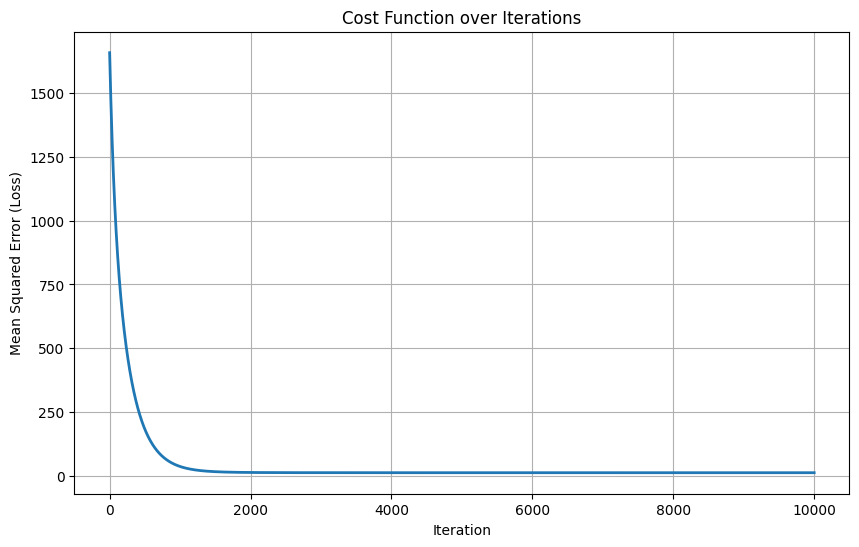

In [34]:
import numpy as np
import matplotlib.pyplot as plt

class LinearRegressionVerbose:
    def __init__(self, learning_rate=0.01, iterations=10000):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.random.randn(n_features) * 0.01
        self.bias = 0
        self.loss_history = []
        
        initial_loss = np.sum((y - (np.dot(X, self.weights) + self.bias)) ** 2) / (2 * n_samples)
        print(f"Initial Loss: {initial_loss}")

        for iteration in range(self.iterations):
            y_predicted = np.dot(X, self.weights) + self.bias
            loss = (1 / (2 * n_samples)) * np.sum((y - y_predicted) ** 2)
            self.loss_history.append(loss)

            dw = -(2 / n_samples) * np.dot(X.T, (y - y_predicted))
            db = -(2 / n_samples) * np.sum(y - y_predicted)

            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

            if iteration % 1000 == 0:
                print(f"Iteration {iteration}: Loss = {loss}")
        
        final_loss = (1 / (2 * n_samples)) * np.sum((y - (np.dot(X, self.weights) + self.bias)) ** 2)
        print(f"Final Loss after {self.iterations} iterations: {final_loss}")

        return self.loss_history

    def predict(self, X):
        predictions = np.dot(X, self.weights) + self.bias
        print(f"Predictions: {predictions[:5]} (showing first 5)")
        return predictions

    def score(self, X, y):
        y_predicted = self.predict(X)
        mse = np.mean((y - y_predicted) ** 2) / 2
        print(f"Mean Squared Error: {mse}")
        return mse


my_model = LinearRegressionVerbose(learning_rate=0.001, iterations=10000)

loss_history = my_model.fit(X_train_normalized, y_train)

y_train_pred = my_model.predict(X_train_normalized)
y_test_pred = my_model.predict(X_test_normalized)

train_mse = my_model.score(X_train_normalized, y_train)
test_mse = my_model.score(X_test_normalized, y_test)

plt.figure(figsize=(10, 6))
plt.plot(range(len(loss_history)), loss_history, linewidth=2)
plt.xlabel('Iteration')
plt.ylabel('Mean Squared Error (Loss)')
plt.title('Cost Function over Iterations')
plt.grid(True)
plt.show()


In [33]:


print(f"Mean Squared Error on Training Set: {train_mse}")
print(f"Mean Squared Error on Test Set: {test_mse}")


Mean Squared Error on Training Set: 13.316122310253009
Mean Squared Error on Test Set: 12.050946668620796


## Part B: Regularised linear regression with scikit-learn
Plain Linear Regression vs **Ridge** (L2), **Lasso** (L1) and **Elastic Net** (L1 + L2) for α ∈ {0.01, 0.1, 1, 10, 100}, plus coefficient paths showing how the learned weights shrink as α grows.

In [46]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error

from sklearn.linear_model import ElasticNet

### Linear Regression (scikit-learn)

In [ ]:
lr_model = LinearRegression()


lr_model.fit(X_train, y_train)
y_train_pred = lr_model.predict(X_train)
y_test_pred = lr_model.predict(X_test)

train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
print(f"Mean Squared Error on Training Set: {train_mse/2:.4f}")
print(f"Mean Squared Error on Test Set: {test_mse/2:.4f}")

Mean Squared Error on Training Set: 13.3140
Mean Squared Error on Test Set: 12.0721


### Ridge (L2)

Alpha: 0.01
Train MSE: 13.3140, Test MSE: 12.0721

Alpha: 0.1
Train MSE: 13.3140, Test MSE: 12.0721

Alpha: 1
Train MSE: 13.3140, Test MSE: 12.0724

Alpha: 10
Train MSE: 13.3173, Test MSE: 12.0780

Alpha: 100
Train MSE: 13.5092, Test MSE: 12.2673



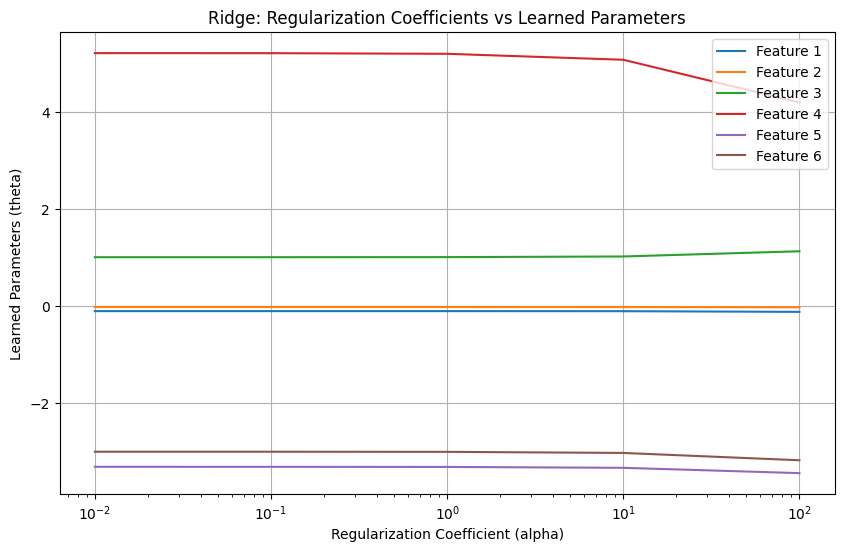

In [ ]:

alphas = [0.01, 0.1, 1, 10, 100]

ridge_coefficients = []
train_mse_list = []
test_mse_list = []

for alpha in alphas:
    ridge_model = Ridge(alpha=alpha)
  
    ridge_model.fit(X_train, y_train)
  
    ridge_coefficients.append(ridge_model.coef_)
    y_train_pred = ridge_model.predict(X_train)
    y_test_pred = ridge_model.predict(X_test)
    
    train_mse = (mean_squared_error(y_train, y_train_pred))/2
    test_mse = (mean_squared_error(y_test, y_test_pred))/2
    
    train_mse_list.append(train_mse)
    test_mse_list.append(test_mse)
    
    print(f"Alpha: {alpha}")
    print(f"Train MSE: {train_mse:.4f}, Test MSE: {test_mse:.4f}\n")

ridge_coefficients = np.array(ridge_coefficients)

plt.figure(figsize=(10, 6))
for i in range(ridge_coefficients.shape[1]):
    plt.plot(alphas, ridge_coefficients[:, i], label=f'Feature {i+1}')

plt.xscale('log')  
plt.xlabel('Regularization Coefficient (alpha)')
plt.ylabel('Learned Parameters (theta)')
plt.title('Ridge: Regularization Coefficients vs Learned Parameters')
plt.legend(loc='best')
plt.grid(True)
plt.show()


### Lasso (L1)

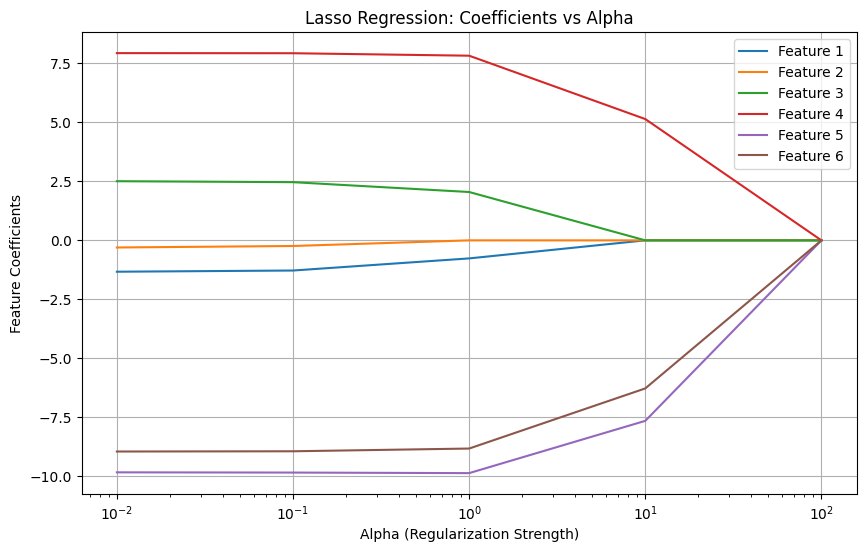

{'Training MSE': [np.float64(13.314050773492554), np.float64(13.322860796183242), np.float64(14.03356459473052), np.float64(68.58191566196322), np.float64(429.58415385093707)], 'Testing MSE': [np.float64(12.073455371022977), np.float64(12.097491213265284), np.float64(12.834045655001137), np.float64(62.70665525361713), np.float64(392.8632951064597)]}


In [ ]:

train_mse_lasso = []
test_mse_lasso = []
coefficients_lasso = []

for reg_strength in alphas:
    lasso_reg = Lasso(alpha=reg_strength, max_iter=10000)
    lasso_reg.fit(X_train_normalized, y_train)
    predictions_train = lasso_reg.predict(X_train_normalized)
    predictions_test = lasso_reg.predict(X_test_normalized)

    train_mse_lasso.append(mean_squared_error(y_train, predictions_train) / 2)
    test_mse_lasso.append(mean_squared_error(y_test, predictions_test) / 2)
    

    coefficients_lasso.append(lasso_reg.coef_)

coefficients_lasso = np.array(coefficients_lasso)

plt.figure(figsize=(10, 6))
for feature_index in range(coefficients_lasso.shape[1]):
    plt.plot(alphas, coefficients_lasso[:, feature_index], linestyle='-', label=f'Feature {feature_index + 1}')

plt.xscale('log')
plt.xlabel('Alpha (Regularization Strength)')
plt.ylabel('Feature Coefficients')
plt.title('Lasso Regression: Coefficients vs Alpha')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

results_mse = {'Training MSE': train_mse_lasso, 'Testing MSE': test_mse_lasso}
print(results_mse)


### Elastic Net (L1 + L2, `l1_ratio = 0.5`)

In [48]:
elastic_net_alphas = [0.01, 0.1, 1, 10, 100]

elastic_net_train_mse = []
elastic_net_test_mse = []

for alpha in elastic_net_alphas:

    elastic_net_model = ElasticNet(alpha=alpha, l1_ratio=0.5, max_iter=10000)

    elastic_net_model.fit(X_train_normalized, y_train)

    y_train_pred = elastic_net_model.predict(X_train_normalized)
    y_test_pred = elastic_net_model.predict(X_test_normalized)

    train_mse = mean_squared_error(y_train, y_train_pred) / 2
    test_mse = mean_squared_error(y_test, y_test_pred) / 2
    elastic_net_train_mse.append(train_mse)
    elastic_net_test_mse.append(test_mse)
    print(f"Alpha: {alpha}")
    print(f"Train MSE: {train_mse:.4f}, Test MSE: {test_mse:.4f}\n")


Alpha: 0.01
Train MSE: 13.3166, Test MSE: 12.0615

Alpha: 0.1
Train MSE: 13.5247, Test MSE: 12.1788

Alpha: 1
Train MSE: 22.5022, Test MSE: 20.1877

Alpha: 10
Train MSE: 187.5321, Test MSE: 170.4584

Alpha: 100
Train MSE: 429.5842, Test MSE: 392.8633



## Summary
- **The from-scratch model matches scikit-learn.** Gradient descent reaches a test cost of **12.05** vs **12.07** for scikit-learn's closed-form `LinearRegression` (train: 13.32 vs 13.31). That is a test RMSE of about **4.9 points** on a 0–100 scale (R² ≈ 0.97).
- **The cost curve** drops from ~1,656 to ~13 within ~3,000 iterations, then plateaus. This confirms that the gradients and the learning rate are correct.
- **Regularisation doesn't help here.** With only 6 features and 800 training rows the plain model doesn't overfit (the test cost is even lower than the train cost), so small α values leave the error unchanged and larger ones only add bias.
- **Lasso vs Elastic Net:** at α = 10 Lasso's test cost rises to 62.7 and Elastic Net's to 170.5. At α = 100 both shrink every coefficient to 0 and simply predict the mean (cost ≈ 393).
- **Note:** Ridge was fit on the raw (unscaled) features, while Lasso and Elastic Net used the standardised ones. Because the raw features have large variances, the same α penalises Ridge far less, which is why its error barely changes even at α = 100.